# Netflix Data Visualization

Exploring Netflix's catalogue of movies and TV shows (6,234 titles, up to 2019) to understand what content it offers.

1. **Data preparation:** unzip the dataset and rename it to `Netflix_shows_movies`
2. **Data cleaning:** handle missing values
3. **Data exploration:** describe the data and run statistical analysis
4. **Data visualization:** most watched genres and the distribution of ratings (Seaborn, Pyplot and Matplotlib)

The ratings chart is recreated in R in `ratings_distribution.R`.

In [101]:
%pip install pandas matplotlib seaborn


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [102]:
import zipfile
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------
ZIP_FILE = Path("netflix_data.zip")
DATA_FILE = Path("Netflix_shows_movies.csv")
CHART_DIR = Path("charts")
TOP_N = 10

MOVIE_COLOR, TV_COLOR = "#2a78d6", "#eb6834"     # Colour-blind-safe blue / orange pair
TYPE_PALETTE = {"Movie": MOVIE_COLOR, "TV Show": TV_COLOR}

sns.set_theme(style="whitegrid")
mpl.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 13, "figure.dpi": 100})
CHART_DIR.mkdir(exist_ok=True)

## 1. Data preparation

Extract the CSV from `netflix_data.zip`, then rename it to `Netflix_shows_movies.csv`.

In [103]:
def prepare_data(zip_path, target_path):
    """Unzip the dataset and rename the extracted CSV to the target file name."""
    try:
        with zipfile.ZipFile(zip_path) as archive:
            csv_files = [name for name in archive.namelist() if name.lower().endswith(".csv")]
            if len(csv_files) != 1:
                raise ValueError(f"Expected one CSV in {zip_path}, found {len(csv_files)}")
            extracted = Path(archive.extract(csv_files[0]))
    except FileNotFoundError:
        raise FileNotFoundError(f"'{zip_path}' not found. Place it in the same folder as this notebook.") from None
    except zipfile.BadZipFile:
        raise ValueError(f"'{zip_path}' is not a valid zip file") from None

    extracted.replace(target_path)      # Rename (overwrites any earlier copy)
    return target_path


data_path = prepare_data(ZIP_FILE, DATA_FILE)
netflix_raw = pd.read_csv(data_path)
print(f"Unzipped and renamed to '{data_path}': {netflix_raw.shape[0]:,} rows x {netflix_raw.shape[1]} columns")
netflix_raw.head()

Unzipped and renamed to 'Netflix_shows_movies.csv': 6,234 rows x 12 columns


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China","September 9, 2019",2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,"September 9, 2016",2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,"September 8, 2018",2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob..."
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,"September 8, 2018",2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,"September 8, 2017",2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...


## 2. Data cleaning

First, check which columns have missing values.

In [104]:
missing = netflix_raw.isna().sum()
missing_report = pd.DataFrame({
    "missing": missing,
    "percent": (missing / len(netflix_raw) * 100).round(1),
})
missing_report[missing_report["missing"] > 0].sort_values("missing", ascending=False)

,missing,percent
director,1969,31.6
cast,570,9.1
country,476,7.6
date_added,11,0.2
rating,10,0.2


How each case is handled:

| Column | Missing | Approach | Why |
|---|---|---|---|
| `director`, `cast`, `country` | 8–32% | Fill with `"Unknown"` | Too many to drop. The title is still useful for genre and rating analysis. |
| `date_added`, `rating` | 20 rows in total (0.3%) | Drop the rows | Too few to affect results, and a rating can't be reliably guessed |

The cleaning also:

- Merges `UR` (Unrated) into `NR` (Not Rated), since both mean the title has no rating.
- Converts `date_added` to a date.
- Splits `duration` into a number and a unit: minutes for movies, seasons for TV shows.

In [105]:
def clean_data(df):
    """Handle missing values and tidy columns for analysis."""
    df = df.drop_duplicates().copy()
    df[["director", "cast", "country"]] = df[["director", "cast", "country"]].fillna("Unknown")
    df = df.dropna(subset=["date_added", "rating"])

    df["rating"] = df["rating"].replace({"UR": "NR"})
    df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="%B %d, %Y")
    df["duration_value"] = df["duration"].str.extract(r"(\d+)", expand=False).astype(int)
    df["duration_unit"] = df["type"].map({"Movie": "minutes", "TV Show": "seasons"})
    return df.reset_index(drop=True)

netflix = clean_data(netflix_raw)
print(f"Rows: {len(netflix_raw):,} -> {len(netflix):,} ({len(netflix_raw) - len(netflix)} dropped)")
print(f"Missing values remaining: {netflix.isna().sum().sum()}")
netflix.head()

Rows: 6,234 -> 6,214 (20 dropped)
Missing values remaining: 0


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,duration_value,duration_unit
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China",2019-09-09,2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...,90,minutes
1,80117401,Movie,Jandino: Whatever it Takes,Unknown,Jandino Asporaat,United Kingdom,2016-09-09,2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...,94,minutes
2,70234439,TV Show,Transformers Prime,Unknown,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,2018-09-08,2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob...",1,seasons
3,80058654,TV Show,Transformers: Robots in Disguise,Unknown,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,2018-09-08,2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...,1,seasons
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,2017-09-08,2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...,99,minutes


## 3. Data exploration

### Overview

In [106]:
netflix.info()

<class 'pandas.DataFrame'>
RangeIndex: 6214 entries, 0 to 6213
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   show_id         6214 non-null   int64         
 1   type            6214 non-null   str           
 2   title           6214 non-null   str           
 3   director        6214 non-null   str           
 4   cast            6214 non-null   str           
 5   country         6214 non-null   str           
 6   date_added      6214 non-null   datetime64[us]
 7   release_year    6214 non-null   int64         
 8   rating          6214 non-null   str           
 9   duration        6214 non-null   str           
 10  listed_in       6214 non-null   str           
 11  description     6214 non-null   str           
 12  duration_value  6214 non-null   int64         
 13  duration_unit   6214 non-null   str           
dtypes: datetime64[us](1), int64(3), str(10)
memory usage: 679.8 KB


In [107]:
#netflix.describe(include="all")#.T[["count", "unique", "top", "freq", "mean", "std", "min", "max"]]

### Movies vs TV shows

In [108]:
type_counts = netflix["type"].value_counts()
pd.DataFrame({"titles": type_counts, "percent": (type_counts / len(netflix) * 100).round(1)})

,titles,percent
type,,
Movie,4257,68.5
TV Show,1957,31.5


### Statistical analysis

**Release year:** how recent is the catalogue?

In [109]:
release = netflix["release_year"]
print(f"Mean {release.mean():.1f} | Median {release.median():.0f} | Std {release.std():.1f} | "
      f"Range {release.min()}-{release.max()} | Skew {release.skew():.2f}")
print(f"Released since 2015: {(release >= 2015).mean():.0%} of titles")

Mean 2013.4 | Median 2016 | Std 8.8 | Range 1925-2020 | Skew -3.70
Released since 2015: 68% of titles


**Duration:** movie runtimes in minutes and TV show lengths in seasons.

In [110]:
netflix.groupby("type")["duration_value"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
Movie,4257.0,99.2,28.1,3.0,86.0,98.0,115.0,312.0
TV Show,1957.0,1.8,1.6,1.0,1.0,1.0,2.0,15.0


**Titles added per year:** how fast the catalogue grew.

In [111]:
netflix["date_added"].dt.year.value_counts().sort_index().to_frame("titles added").T

date_added,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
titles added,2,2,1,13,7,12,25,88,453,1297,1781,2349,184


**Top producing countries:** titles can list several countries, so each one is counted.

In [112]:
countries = netflix["country"].str.split(",").explode().str.strip()
countries[countries != "Unknown"].value_counts().head(TOP_N).to_frame("titles")

,titles
country,
United States,2601
India,838
United Kingdom,601
Canada,318
France,271
Japan,229
Spain,178
South Korea,162
Germany,151


**Movie runtime by rating:** do content ratings relate to film length? (Ratings with at least 30 movies.)

In [113]:
movies = netflix[netflix["type"] == "Movie"]
(movies.groupby("rating")["duration_value"]
       .agg(["count", "median", "mean"])
       .query("count >= 30")
       .sort_values("median", ascending=False)
       .round(1))

,count,median,mean
rating,,,
PG-13,286,105.5,108.9
TV-14,1038,105.0,108.1
R,506,102.0,106.2
TV-PG,432,96.0,97.9
TV-MA,1348,95.0,95.3
NR,209,94.0,95.6
PG,183,94.0,97.8
G,36,81.5,85.4
TV-G,80,68.5,67.8


Movies for older audiences run longer: `PG-13`, `TV-14` and `R` films have a median of 102–106 minutes, against 46–62 minutes for children's ratings (`TV-Y`, `TV-Y7`). Most TV shows on Netflix have just **one season** (median 1, mean 1.8).

## 4. Data visualization

### Most watched genres

The dataset has no viewing figures, so **the number of titles in each genre is used as a stand-in for what's most watched**: Netflix stocks more of what its audience watches. Titles often list several genres (e.g. *"Dramas, International Movies"*), so each genre a title lists is counted.

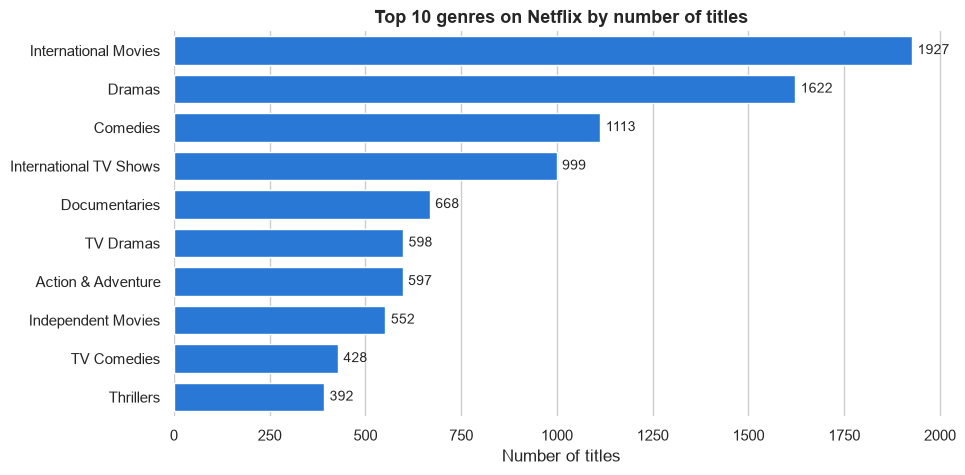

In [114]:
genres = netflix["listed_in"].str.split(",").explode().str.strip()
#print(genres.value_counts())
top_genres = genres.value_counts().head(TOP_N)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=top_genres.values, y=top_genres.index, color=MOVIE_COLOR, saturation=1, width=0.75, ax=ax)
ax.bar_label(ax.containers[0], padding=4, fontsize=10)
ax.set(title=f"Top {TOP_N} genres on Netflix by number of titles", xlabel="Number of titles", ylabel="")
ax.grid(axis="y", visible=False)
sns.despine(left=True, bottom=True)
# plt.tight_layout() # Make sure the chart is not cut off
fig.savefig(CHART_DIR / "top_genres.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaways:**

- **International Movies** and **Dramas** lead by a wide margin, followed by Comedies and International TV Shows.
- International content makes up two of the top four genres, which reflects Netflix's global catalogue.

### Ratings distribution

TV ratings (`TV-MA`, `TV-14`, …) and film ratings (`R`, `PG-13`, …) both appear, so the chart is split by type. As a guide:

- `TV-MA` and `R` are for adults.
- `TV-14` and `PG-13` suit teens.
- `TV-Y`, `TV-Y7` and `G` suit children.

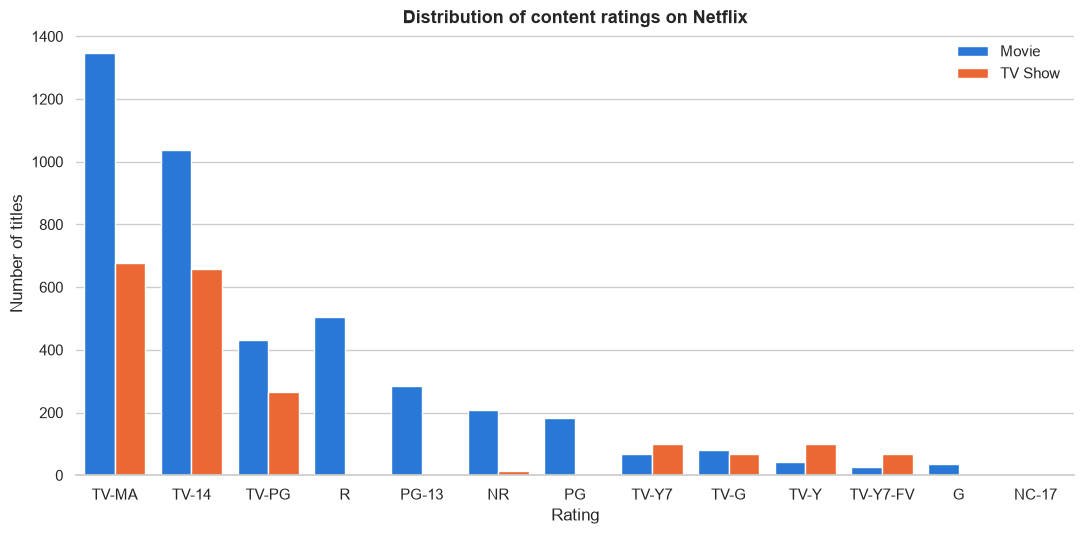

In [115]:
rating_order = netflix["rating"].value_counts().index

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.countplot(data=netflix, x="rating", hue="type", order=rating_order,
              palette=TYPE_PALETTE, saturation=1, width=0.8, ax=ax)
ax.set(title="Distribution of content ratings on Netflix", xlabel="Rating", ylabel="Number of titles")
ax.legend(title="", frameon=False)
ax.grid(axis="x", visible=False)
sns.despine(left=True)
plt.tight_layout()
fig.savefig(CHART_DIR / "ratings_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [116]:
rating_share = (netflix["rating"].value_counts(normalize=True) * 100).round(1)
print(f"TV-MA + TV-14 make up {rating_share[['TV-MA', 'TV-14']].sum():.0f}% of all titles")
pd.crosstab(netflix["rating"], netflix["type"]).loc[rating_order].T

TV-MA + TV-14 make up 60% of all titles


rating,TV-MA,TV-14,TV-PG,R,PG-13,NR,PG,TV-Y7,TV-G,TV-Y,TV-Y7-FV,G,NC-17
type,,,,,,,,,,,,,
Movie,1348,1038,432,506,286,209,183,69,80,41,27,36,2
TV Show,677,657,267,2,0,15,1,99,69,101,68,1,0


**Takeaways:**

- **TV-MA** (mature audiences) is the most common rating, followed by **TV-14**. Together they cover over half the catalogue, so Netflix leans toward teen and adult viewers.
- Theatrical film ratings (`R`, `PG-13`, `PG`, `G`) apply almost entirely to movies: only 4 TV shows carry one.
- Children's content (`TV-Y`, `TV-Y7`, `TV-Y7-FV`) is a small share overall, and the one area where **TV shows outnumber movies**. Kids' content on Netflix is mainly series.

## Summary

- **Data:** unzipped and renamed to `Netflix_shows_movies.csv`. Missing values were filled where too many to drop, and the 20 incomplete rows were dropped.
- **Catalogue:** about two thirds movies, and mostly recent titles.
- **Genres:** International Movies and Dramas dominate.
- **Ratings:** most content is rated for mature or teen audiences.
- **Charts:** saved in `charts/`. The ratings chart is recreated in R by `ratings_distribution.R`.